# Flower Classification Project

Your task is to **classify photos of flowers as roses, sunflowers or tulips**, with only 100 photos per kind of flower to learn from, using **transfer learning**.

# The Business Problem

A garden centre runs a website where customers upload a photo of a flower from their garden and receive a care guide for it: when to water, when to cut it back, which pests to watch for. At the moment, a member of staff looks at every photo and chooses the right guide by hand. The garden centre starts with its three most requested guides, **roses, sunflowers and tulips**, and wants a model that chooses the guide automatically from the photo.

Your model answers this question: given a photo, which of the three flowers does it show? A wrong answer sends a customer the wrong care guide, so at the end you look at **which photos the model gets wrong**, so that the garden centre knows when to trust it and when a member of staff should check the answer.

The model can only answer with one of the three flowers. A photo of a daisy would still receive one of the three labels, so the website has to make clear which flowers the service covers.

# Data Description

The data ships with this repository in the folder `data/`: **390 colour photos**, one JPEG file per photo, sorted into one folder per kind of flower. The name of the folder is the label of the photo.

| Folder | Photos | Description |
| :-- | :-- | :-- |
| `data/train/rose` | 100 | roses, for training |
| `data/train/sunflower` | 100 | sunflowers, for training |
| `data/train/tulip` | 100 | tulips, for training |
| `data/validation/rose` | 20 | roses, for choosing the model |
| `data/validation/sunflower` | 20 | sunflowers, for choosing the model |
| `data/validation/tulip` | 20 | tulips, for choosing the model |
| `data/test/rose` | 10 | roses, **the test set** |
| `data/test/sunflower` | 10 | sunflowers, **the test set** |
| `data/test/tulip` | 10 | tulips, **the test set** |

The photos have different sizes, from 159 to 640 pixels wide, and show the flowers in very different ways: a single flower close up, a whole field, a bunch in a vase, sometimes with people or buildings in the picture.

The photos are part of the [TensorFlow flower photos](https://www.tensorflow.org/datasets/catalog/tf_flowers) collection and were taken from Flickr. Every photo is licensed under [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/); its photographer is listed in `data/LICENSE.txt`.

## Task

1. **Get the data.** Display a few photos of every class from `data/train`.
2. **Load the training and the validation images.** Load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`, with one `image_size` that you use for every model, for example `(160, 160)`. Shuffle the training images with a fixed `seed`; keep the validation images in their order with `shuffle=False`. Do not load `data/test` until step 6.
3. **Explore the training set.** Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?
4. **Repurpose a pretrained network.** Use `MobileNetV2` from `keras.applications` as the pretrained network and repurpose it to classify the three flowers. Plot its learning curves: does it overfit?

> [!IMPORTANT]
> **Every image has to be prepared in exactly the same way**: the same `image_size`, the same `preprocess_input` of the base, and the same frozen base, for the training, the validation and later the test images.

5. **If needed, improve the model with data augmentation**, and compare the validation accuracy with step 4. Choose your best model by its validation accuracy. **Save every model to a file** with `model.save`, for example `models/dense_head.keras`, so that you can load all of them in step 6 with `keras.models.load_model`, even after restarting the notebook.
6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?
7. **Try your model in an app.** The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`, that loads a model from `models/` and classifies a photo that you upload. Start it in a terminal in the repository folder with `uv run streamlit run app.py`, choose your best model, and upload a few flower photos of your own. Does the model get them right? The app works with models that take the raw photos and include their preprocessing, such as `preprocess_input`, as layers.

In [1]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

### 1 . Gettting the Data

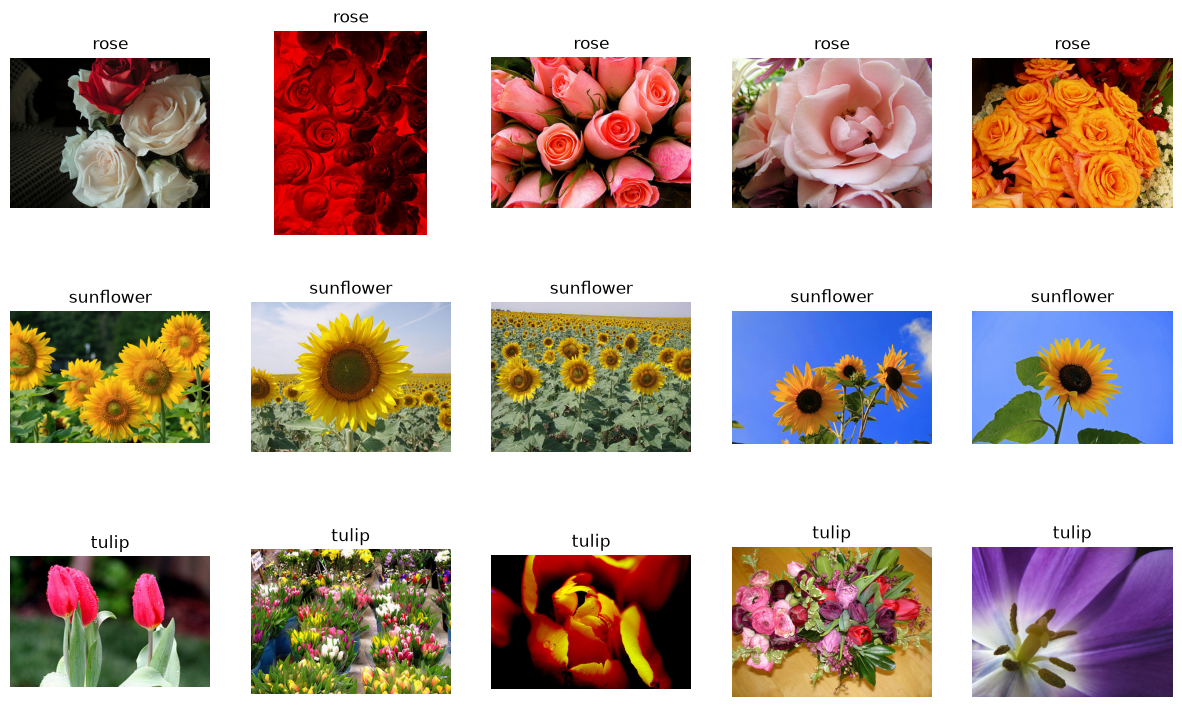

In [2]:
# Your code here

DATA = Path("data")

from PIL import Image

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row, flower in enumerate(["rose", "sunflower", "tulip"]):
    paths = sorted((DATA / "train" / flower).glob("*.jpg"))[:5]
    for col, path in enumerate(paths):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].set_title(flower)
        axes[row, col].axis("off")
plt.show()


In [3]:
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    DATA / "train", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED,
)
val_ds = keras.utils.image_dataset_from_directory(
    DATA / "validation", image_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
    shuffle=False,
)
class_names = train_ds.class_names
print(class_names)


Found 300 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
['rose', 'sunflower', 'tulip']
